# Train/test EC classification

Train a grouped graph classifier using the active manifest and completed graph cache. UniProt accession is the split group so a protein cannot occur in both train and test. Classes represented by a single UniProt accession are retained in training and reported as train-only. Protein graph vectorization shows a progress bar during training and prediction. XGBoost trains directly on sparse features with parallel histogram trees, with a progress bar for the 300 boosting rounds.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (path / "notebooks" / "src" / "enzyme_workflow").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not find the repository root from this notebook's working directory")
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
from enzyme_workflow.classifier import run_classifier


In [2]:
# User parameters
TEST_SIZE = 0.20
RANDOM_STATE = 42
NODE_LABEL_ALPHABET = "aa20"  # aa20, hp2, charge4, physchem5, chem7, or dayhoff6
BASE_ESTIMATOR_KIND = "linear_sgd"  # xgboost, linear_sgd, or random_forest
MAX_SIMPLEX_DIMENSION = 3
MIN_PAIR_DISTANCE = 0
MAX_PAIR_DISTANCE = 4
NBITS = 11
VECTORIZER_PROGRESS = True
CLASSIFIER_PROGRESS = True
N_JOBS = -1  # use all available CPU cores for vectorization and classifier fitting


Fitting classifier on 168 training proteins


Vectorizing protein graphs:   0%|          | 0/168 [00:00<?, ?protein/s]

Predicting 42 test proteins


Vectorizing protein graphs:   0%|          | 0/42 [00:00<?, ?protein/s]

Vectorizing protein graphs:   0%|          | 0/42 [00:00<?, ?protein/s]

Split: StratifiedGroupKFold first fold
Accuracy: 0.333; balanced accuracy: 0.333
Saved run: ./results/ec_level_1_20261118T120605Z


... (2 outputs left out)

,train_samples
1,24
2,24
3,24
4,24
5,24
6,24
7,24


,test_samples
1,6
2,6
3,6
4,6
5,6
6,6
7,6


,precision,recall,f1-score,support
1,0.600000,0.500000,0.545455,6.000000
2,0.333333,0.333333,0.333333,6.000000
3,0.500000,0.166667,0.250000,6.000000
4,0.000000,0.000000,0.000000,6.000000
5,0.176471,0.500000,0.260870,6.000000
6,0.000000,0.000000,0.000000,6.000000
7,0.555556,0.833333,0.666667,6.000000
accuracy,0.333333,0.333333,0.333333,0.333333
macro avg,0.309337,0.333333,0.293761,42.000000
weighted avg,0.309337,0.333333,0.293761,42.000000


,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6,pred_7
true_1,3,1,1,0,0,0,1
true_2,0,2,0,0,4,0,0
true_3,1,0,1,1,3,0,0
true_4,0,0,0,0,4,0,2
true_5,0,2,0,1,3,0,0
true_6,1,1,0,1,2,0,1
true_7,0,0,0,0,1,0,5


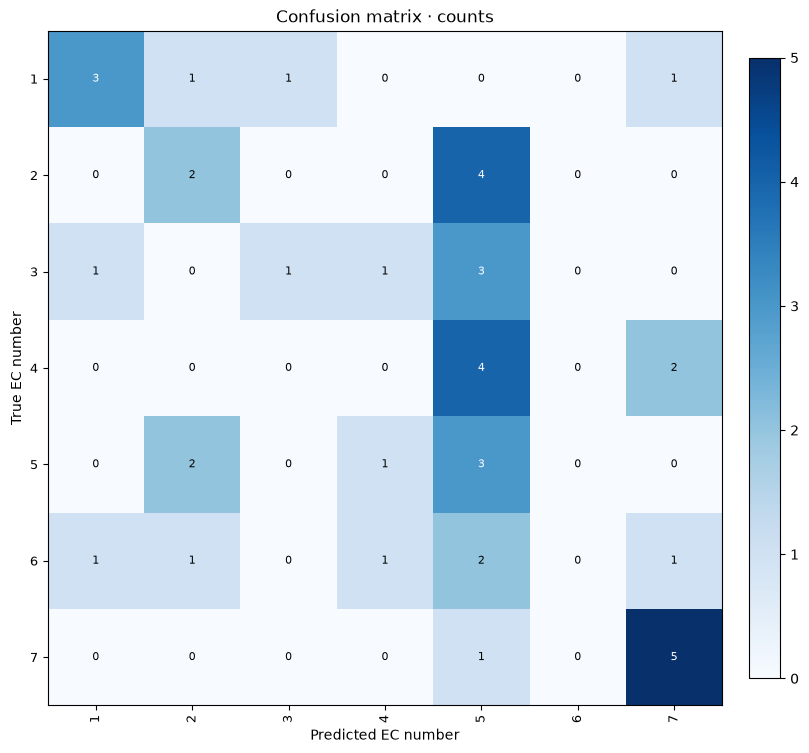

,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6,pred_7
true_1,0.500000,0.166667,0.166667,0.000000,0.000000,0.0,0.166667
true_2,0.000000,0.333333,0.000000,0.000000,0.666667,0.0,0.000000
true_3,0.166667,0.000000,0.166667,0.166667,0.500000,0.0,0.000000
true_4,0.000000,0.000000,0.000000,0.000000,0.666667,0.0,0.333333
true_5,0.000000,0.333333,0.000000,0.166667,0.500000,0.0,0.000000
true_6,0.166667,0.166667,0.000000,0.166667,0.333333,0.0,0.166667
true_7,0.000000,0.000000,0.000000,0.000000,0.166667,0.0,0.833333


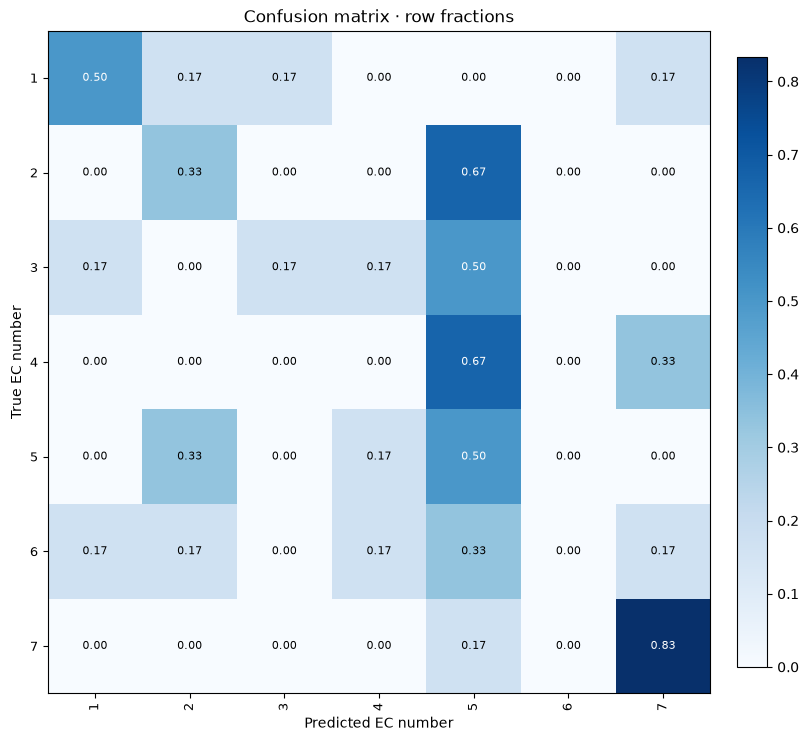

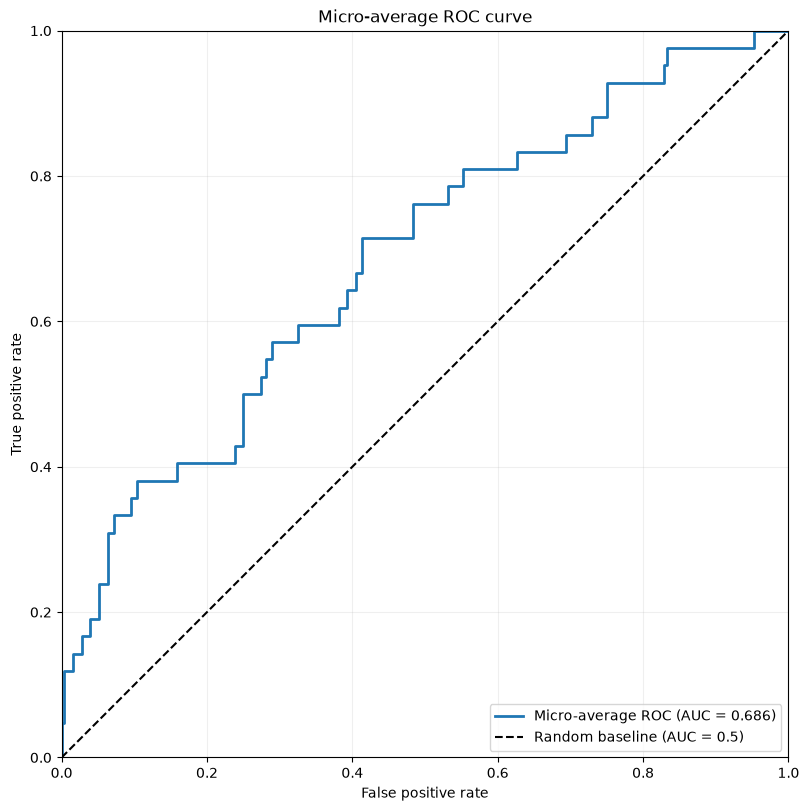

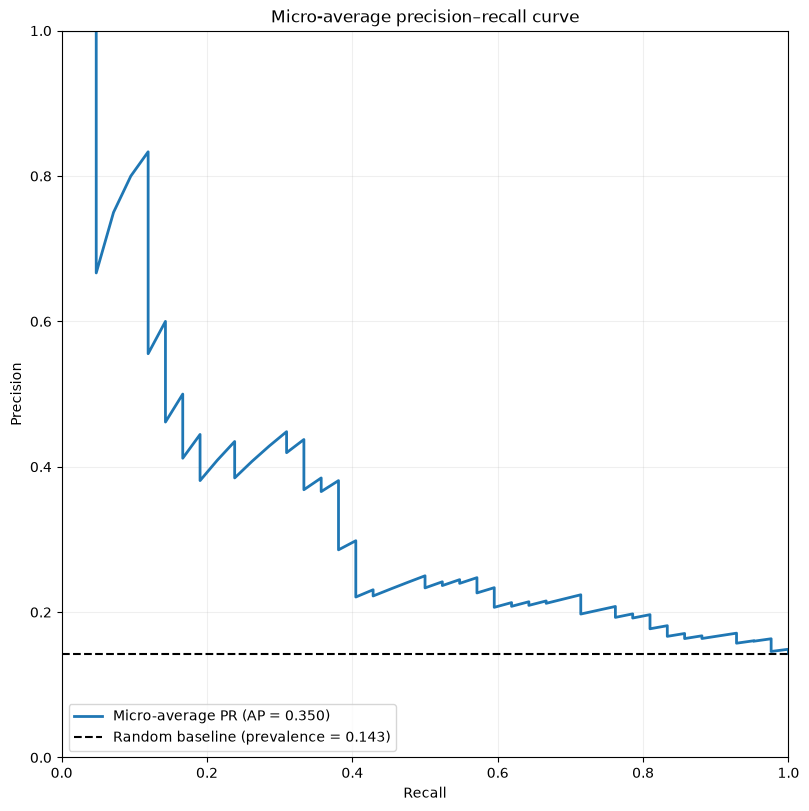

,sample_id,pdb_id,label_asym_id,uniprot_accession,ec_number,protein_name,graph_path,y_true,y_pred,correct
0,4b4o.H,4b4o,H,Q9NRG7,1,Epimerase family protein SDR39U1 (EC 1.1.1.-) ...,.,1,1,True
1,3lc4.B,3lc4,B,P05181,1,Cytochrome P450 2E1 (EC 1.14.14.1) (4-nitrophe...,.,1,1,True
3,7mjc.B,7mjc,B,P30837,1,"Aldehyde dehydrogenase family 1 member B1, mit...",.,1,1,True
9,2vcy.B,2vcy,B,Q9BV79,1,"Enoyl-[acyl-carrier-protein] reductase, mitoch...",.,1,7,False
22,1wmv.A,1wmv,A,Q9NZC7,1,WW domain-containing oxidoreductase (EC 1.1.1....,.,1,3,False


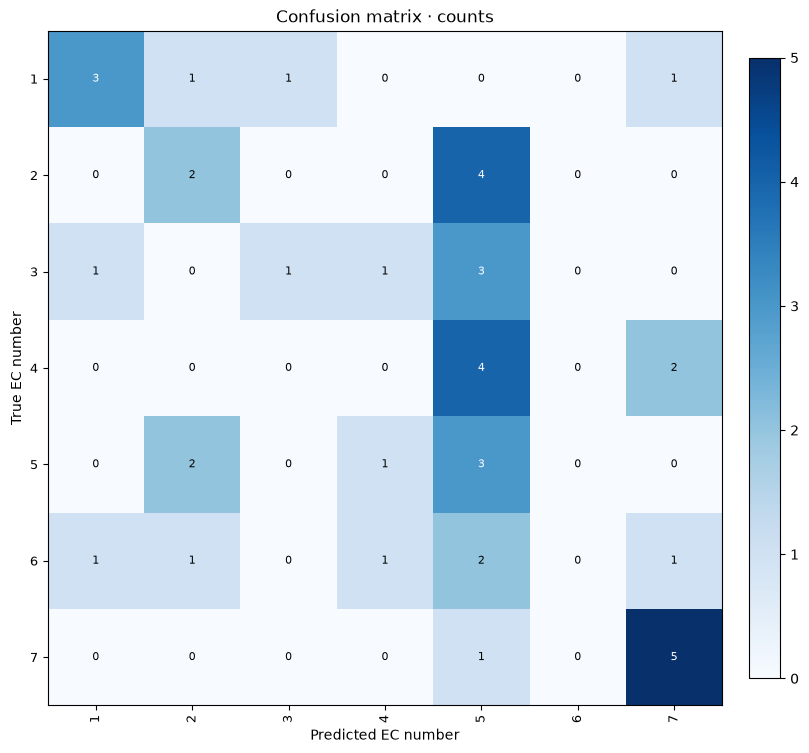

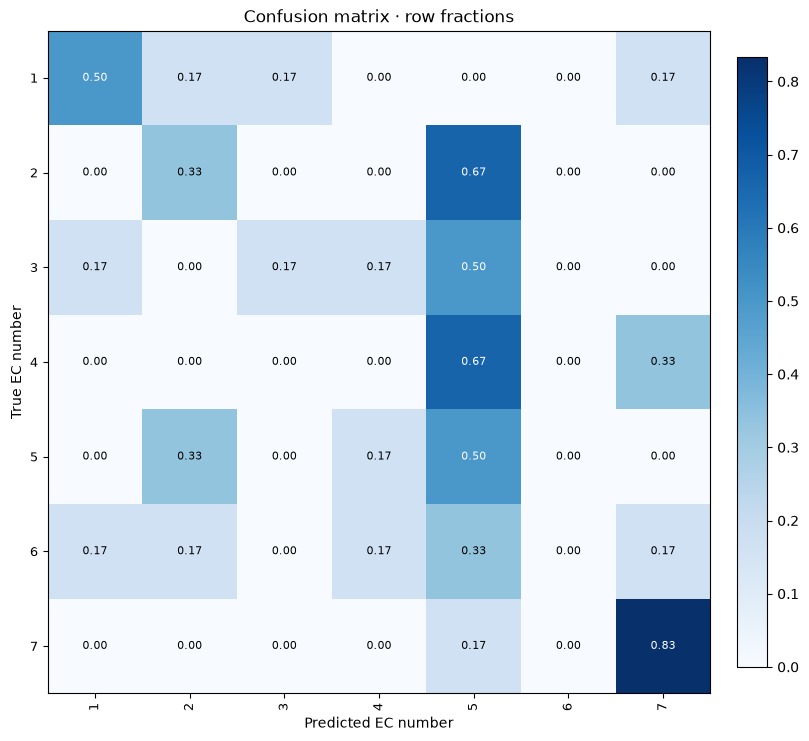

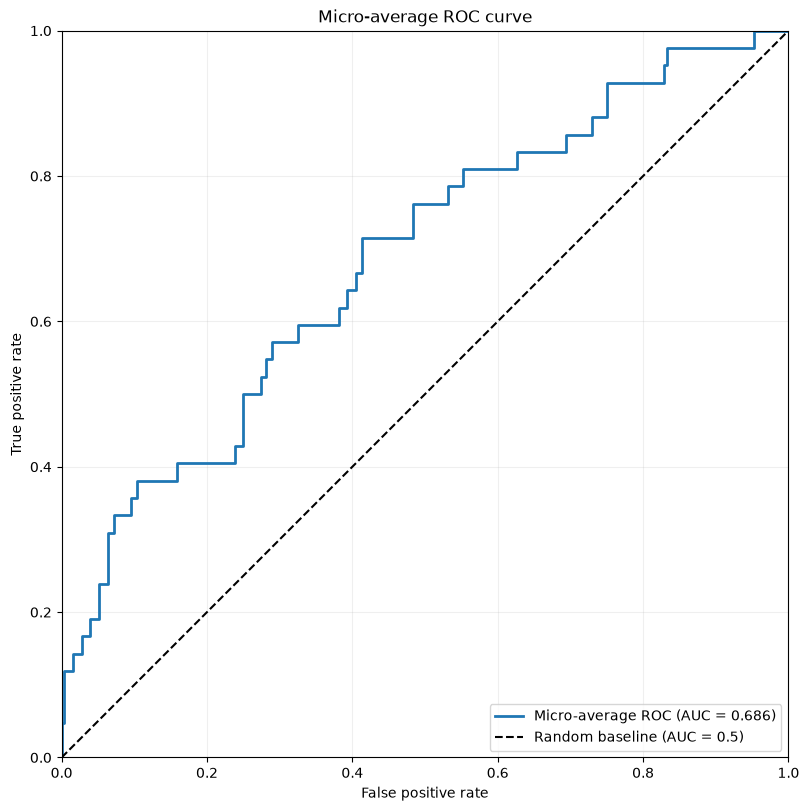

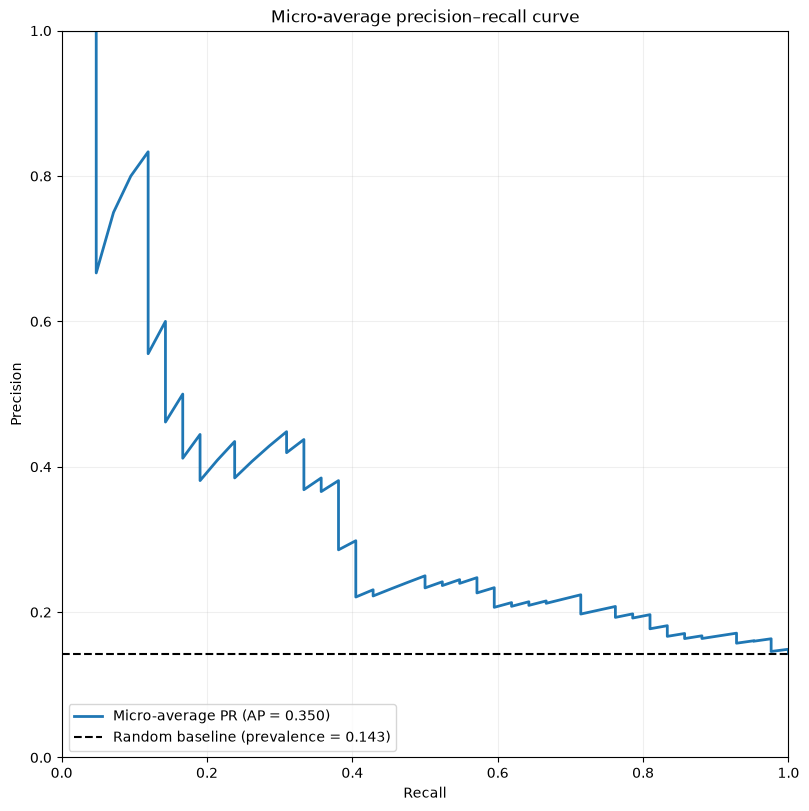

In [3]:
classification = run_classifier(
    PROJECT_ROOT,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    node_label_alphabet=NODE_LABEL_ALPHABET,
    base_estimator_kind=BASE_ESTIMATOR_KIND,
    max_simplex_dimension=MAX_SIMPLEX_DIMENSION,
    min_pair_distance=MIN_PAIR_DISTANCE,
    max_pair_distance=MAX_PAIR_DISTANCE,
    nbits=NBITS,
    vectorizer_progress=VECTORIZER_PROGRESS,
    classifier_progress=CLASSIFIER_PROGRESS,
    n_jobs=N_JOBS,
)
print(f"Split: {classification.split_strategy}")
print(f"Accuracy: {classification.accuracy:.3f}; balanced accuracy: {classification.balanced_accuracy:.3f}")
print(f"Saved run: {classification.run_dir}")
display(classification.class_counts)
display(classification.class_group_counts)
if classification.train_only_classes:
    print("Train-only EC classes (single UniProt group):", classification.train_only_classes)
display(classification.train_counts)
display(classification.test_counts)
display(classification.report)
display(classification.confusion)
display(classification.confusion_figure)
display(classification.confusion_fractions)
display(classification.confusion_fraction_figure)
display(classification.roc_figure)
display(classification.pr_figure)
display(classification.predictions.head())


ROC and PR curves use micro-averaged one-vs-rest scores. The ROC dashed diagonal shows chance-level discrimination; the PR dashed horizontal line shows the positive-label prevalence baseline. Confusion fractions are normalized by true-class row, so each nonempty row sums to one. All four figures use square plotting axes.
